# 3. Spatial Processing and Enhancement

Practice for week 3: contrast stretching, histogram equalization (and why it is neither flat nor
invertible in the discrete case), counting images vs histograms, mean/median as L2/L1 minimizers,
repeated averaging, median vs average on salt-and-pepper noise, and non-local means.

In [1]:
import itertools
from math import comb
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=256):
    y, x = np.mgrid[:n, :n] / n
    img = 0.25 + 0.4 * x + 0.1 * np.sin(6 * np.pi * y)
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.15
    s = (y > 0.7) & (x < 0.45)
    img[s] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 40 * x[s]))
    return img.clip(0, 1)

def psnr(a, b):
    return 10 * np.log10(1 / np.mean((a - b) ** 2))

img = make_image()

## 3.1 Contrast stretching and histogram equalization

A washed-out version of the image uses only gray levels of about 100–150. Contrast stretching
`I2 = (I1 − m) / (M − m) · L` maps `[m, M]` linearly onto the full range. Equalization maps each level
through the cumulative histogram.

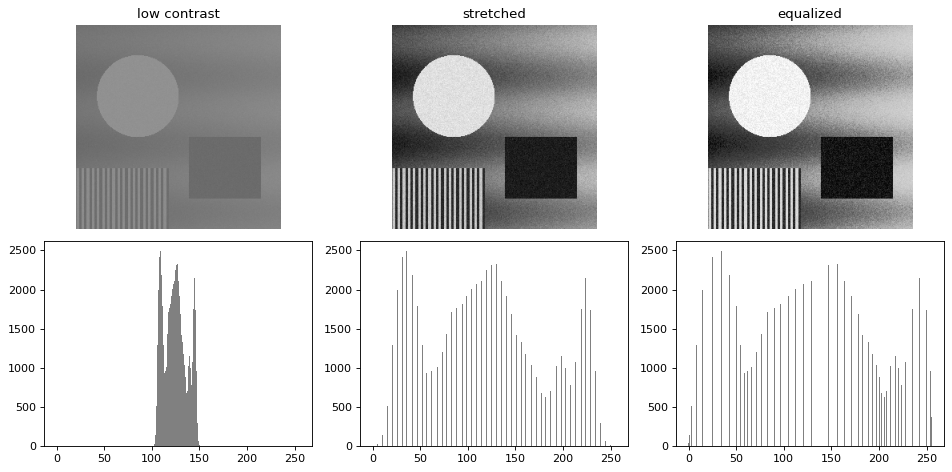

distinct levels: input 50 | equalized 46


In [2]:
low = np.round(100 + 50 * img + rng.normal(0, 1.5, img.shape)).astype(int)
m, M = low.min(), low.max()
stretched = np.round((low - m) / (M - m) * 255).astype(int)

hist = np.bincount(low.ravel(), minlength=256)
cdf = np.cumsum(hist) / low.size
equalized = np.round(255 * cdf[low]).astype(int)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, (u, t) in enumerate([(low, "low contrast"), (stretched, "stretched"), (equalized, "equalized")]):
    axes[0, j].imshow(u, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(t); axes[0, j].axis("off")
    axes[1, j].bar(range(256), np.bincount(u.ravel(), minlength=256), width=1.0, color="gray")
plt.tight_layout(); plt.show()
print("distinct levels: input", len(np.unique(low)), "| equalized", len(np.unique(equalized)))

The equalized histogram is spread out but not flat: all pixels with the same input value go to the same
output value, so a tall bin stays one tall bin. And since several input levels can map to the same output,
the transform is generally not invertible.

## 3.2 How many images, how many histograms?

N pixels with K levels give `K^N` images but only `C(N + K − 1, K − 1)` histograms (ways to put N pixels into
K bins). Brute force for 2 pixels and 3 values:

In [3]:
images = list(itertools.product(range(3), repeat=2))
histograms = {tuple(np.bincount(im, minlength=3)) for im in images}
print(f"images: {len(images)} (3^2 = 9), histograms: {len(histograms)} (C(4, 2) = {comb(4, 2)})")
print(f"a 16x16 binary image: 2^256 = {2 ** 256:.2e} images, only {comb(257, 1)} histograms")

images: 9 (3^2 = 9), histograms: 6 (C(4, 2) = 6)
a 16x16 binary image: 2^256 = 1.16e+77 images, only 257 histograms


## 3.3 Mean, median and the norms they minimize

The mean minimizes the sum of squared differences (L2), the median the sum of absolute differences (L1).
That is why the median ignores outliers.

In [4]:
v = np.array([3, 4, 4, 5, 6, 7, 40.0])
c = np.linspace(0, 45, 4501)
l2 = ((v[:, None] - c) ** 2).sum(0); l1 = np.abs(v[:, None] - c).sum(0)
print(f"argmin L2 = {c[l2.argmin()]:.2f} (mean {v.mean():.2f}), argmin L1 = {c[l1.argmin()]:.2f} (median {np.median(v):.2f})")

argmin L2 = 9.86 (mean 9.86), argmin L1 = 5.00 (median 5.00)


## 3.4 Repeated averaging

A 3×3 average applied again and again blurs more and more. With periodic boundaries the mean is preserved
exactly, so the image converges to a constant equal to its global mean.

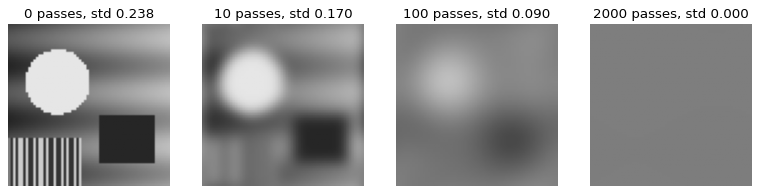

global mean 0.4923, value after 2000 passes 0.4923 ± 1.8e-04


In [5]:
box3 = lambda u: sum(np.roll(np.roll(u, dy, 0), dx, 1) for dy in (-1, 0, 1) for dx in (-1, 0, 1)) / 9
u = img[::4, ::4].copy()
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for it, a in zip([0, 10, 100, 2000], axes):
    w = u.copy()
    for _ in range(it): w = box3(w)
    a.imshow(w, cmap="gray", vmin=0, vmax=1); a.axis("off"); a.set_title(f"{it} passes, std {w.std():.3f}")
plt.show()
print(f"global mean {u.mean():.4f}, value after 2000 passes {w.mean():.4f} ± {w.std():.1e}")

## 3.5 Median vs average on salt-and-pepper noise

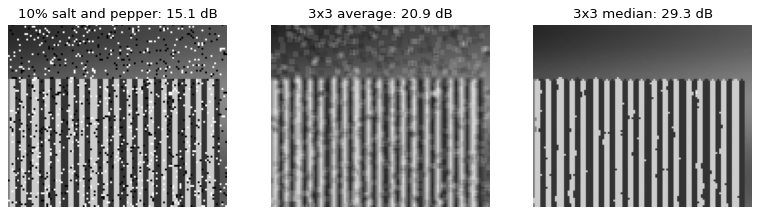

In [6]:
def median3(u):
    return np.median(sliding_window_view(np.pad(u, 1, mode="edge"), (3, 3)), axis=(-2, -1))

noisy = img.copy()
r = rng.random(img.shape)
noisy[r < 0.05] = 0; noisy[r > 0.95] = 1
avg = sliding_window_view(np.pad(noisy, 1, mode="edge"), (3, 3)).mean((-2, -1))
med = median3(noisy)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(axes, [noisy, avg, med], ["10% salt and pepper", "3x3 average", "3x3 median"]):
    a.imshow(im[150:250, 0:120], cmap="gray", vmin=0, vmax=1); a.axis("off"); a.set_title(f"{t}: {psnr(im, img):.1f} dB")
plt.show()

## 3.6 Non-local means

Each pixel becomes a weighted average of pixels whose *surrounding patches* look similar, not just of its
spatial neighbours. Repeated stripes help each other, so texture is denoised without being blurred.
Applying the filter a second time changes the image again: it is not idempotent.

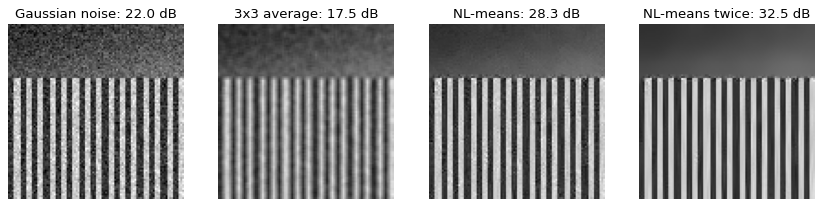

mean |NLM(NLM(x)) - NLM(x)| = 0.0180 -> not idempotent


In [7]:
def nlm(u, h=0.08, patch=2, search=5):
    n, m = u.shape
    P = np.pad(u, patch + search, mode="reflect")
    k = 2 * patch + 1
    base = P[search:search + n + 2 * patch, search:search + m + 2 * patch]
    num = np.zeros_like(u); den = np.zeros_like(u)
    for dy in range(-search, search + 1):
        for dx in range(-search, search + 1):
            sh = P[search + dy:search + dy + n + 2 * patch, search + dx:search + dx + m + 2 * patch]
            d2 = sliding_window_view((base - sh) ** 2, (k, k)).mean((-2, -1))
            w = np.exp(-d2 / h ** 2)
            num += w * sh[patch:patch + n, patch:patch + m]; den += w
    return num / den

crop = img[150:246, 10:106]
gn = crop + rng.normal(0, 0.08, crop.shape)
g_avg = sliding_window_view(np.pad(gn, 1, mode="edge"), (3, 3)).mean((-2, -1))
once = nlm(gn); twice = nlm(once)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for a, im, t in zip(axes, [gn, g_avg, once, twice], ["Gaussian noise", "3x3 average", "NL-means", "NL-means twice"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=1); a.axis("off"); a.set_title(f"{t}: {psnr(im, crop):.1f} dB")
plt.show()
print(f"mean |NLM(NLM(x)) - NLM(x)| = {np.abs(twice - once).mean():.4f} -> not idempotent")